In [1]:
# =========================
# Core libraries
# =========================
import numpy as np
import pandas as pd

# =========================
# Visualization
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# Warnings & settings
# =========================
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# =========================
# Scikit-learn utilities
# =========================
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    OrdinalEncoder
)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# =========================
# Environment (Kaggle)
# =========================
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/vitamin-deficiency-disease-prediction-dataset/vitamin_deficiency_disease_dataset_20260123.csv



# **DATA PREPROCESSING**



## **Initial Data Inspection**

In [2]:
df = pd.read_csv('/kaggle/input/vitamin-deficiency-disease-prediction-dataset/vitamin_deficiency_disease_dataset_20260123.csv')

print("First 5 Rows")
print("=" * 60)
display(df.head())

print("\n Last 5 Rows")
print("=" * 60)
display(df.tail())

First 5 Rows


,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,vitamin_a_percent_rda,vitamin_c_percent_rda,vitamin_d_percent_rda,vitamin_e_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,calcium_percent_rda,iron_percent_rda,hemoglobin_g_dl,serum_vitamin_d_ng_ml,serum_vitamin_b12_pg_ml,serum_folate_ng_ml,symptoms_count,symptoms_list,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,disease_diagnosis,has_multiple_deficiencies
0,79,Male,24.8,Former,NaN,Active,Vegetarian,High,High,Mid,119.1,147.3,152.88,97.5,102.5,188.9,108.3,97.4,13.5,39.3,356.4,23.3,0,NaN,0,0,0,0,0,0,0,0,Healthy,0
1,77,Female,39.9,Former,Moderate,Light,Omnivore,Low,Low,Low,85.7,57.5,32.76,82.7,62.6,51.0,42.6,102.5,15.4,8.9,303.0,5.3,1,bone_pain,0,0,0,1,0,0,0,0,Rickets_Osteomalacia,0
2,24,Male,26.4,Former,Heavy,Moderate,Omnivore,Low,High,High,48.3,152.1,94.99,169.3,136.2,116.6,136.3,86.4,14.1,29.9,578.0,16.3,2,dry_skin;night_blindness,1,0,0,0,0,0,0,0,Healthy,0
3,69,Male,23.1,Never,Heavy,Moderate,Vegetarian,High,Low,Low,75.8,51.0,51.48,85.7,31.8,66.5,76.5,60.8,12.3,20.2,144.8,9.2,2,numbness_tingling;memory_problems,0,0,0,0,0,1,1,0,Anemia,0
4,63,Male,29.6,Never,NaN,Moderate,Vegetarian,Moderate,High,Low,93.3,111.5,62.90,155.6,72.6,124.9,69.4,71.9,15.1,20.7,348.2,13.4,0,NaN,0,0,0,0,0,0,0,0,Healthy,0



 Last 5 Rows


,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,vitamin_a_percent_rda,vitamin_c_percent_rda,vitamin_d_percent_rda,vitamin_e_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,calcium_percent_rda,iron_percent_rda,hemoglobin_g_dl,serum_vitamin_d_ng_ml,serum_vitamin_b12_pg_ml,serum_folate_ng_ml,symptoms_count,symptoms_list,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,disease_diagnosis,has_multiple_deficiencies
3995,25,Female,21.6,Former,Heavy,Active,Pescatarian,Moderate,Middle,High,41.4,66.1,111.50,99.8,72.8,77.0,142.0,72.9,15.3,34.8,346.7,9.2,1,night_blindness,1,0,0,0,0,0,0,0,Healthy,0
3996,50,Male,29.5,Former,Moderate,Sedentary,Vegetarian,Low,High,Low,146.3,113.0,72.66,91.5,99.4,120.1,101.4,94.1,13.8,19.9,272.2,15.0,0,NaN,0,0,0,0,0,0,0,0,Healthy,0
3997,34,Female,24.8,Never,NaN,Active,Pescatarian,Moderate,Low,Low,77.0,39.8,76.10,43.2,41.6,62.7,43.9,53.7,13.4,21.4,100.0,4.8,3,numbness_tingling;memory_problems;fatigue,0,1,0,0,0,1,1,0,Anemia,0
3998,39,Female,26.9,Former,Heavy,Active,Omnivore,High,Low,High,41.1,71.2,75.79,32.5,53.4,47.3,15.4,56.3,14.1,23.5,138.8,6.1,2,dry_skin;night_blindness,1,0,0,0,0,0,0,0,Anemia,0
3999,41,Female,28.0,Current,NaN,Sedentary,Omnivore,High,High,High,135.6,63.7,155.61,170.0,38.8,127.7,130.9,130.5,13.3,55.9,122.7,11.0,1,memory_problems,0,0,0,0,0,0,1,0,Anemia,0


In [3]:
print("Dataset Shape")
print("=" * 60)
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")


Dataset Shape
Rows    : 4000
Columns : 34


In [4]:
print("List of All Columns")
print("=" * 50)
for col in df.columns:
    print(col)

List of All Columns
age
gender
bmi
smoking_status
alcohol_consumption
exercise_level
diet_type
sun_exposure
income_level
latitude_region
vitamin_a_percent_rda
vitamin_c_percent_rda
vitamin_d_percent_rda
vitamin_e_percent_rda
vitamin_b12_percent_rda
folate_percent_rda
calcium_percent_rda
iron_percent_rda
hemoglobin_g_dl
serum_vitamin_d_ng_ml
serum_vitamin_b12_pg_ml
serum_folate_ng_ml
symptoms_count
symptoms_list
has_night_blindness
has_fatigue
has_bleeding_gums
has_bone_pain
has_muscle_weakness
has_numbness_tingling
has_memory_problems
has_pale_skin
disease_diagnosis
has_multiple_deficiencies


In [5]:
print("Datatype of Each Column")
print("=" * 60)
display(df.dtypes.to_frame(name="Data Type"))

Datatype of Each Column


,Data Type
age,int64
gender,object
bmi,float64
smoking_status,object
alcohol_consumption,object
exercise_level,object
diet_type,object
sun_exposure,object
income_level,object
latitude_region,object


In [6]:
print("\nInformation of All Columns")
print("=" * 60)
df.info()
print("=" * 60)


Information of All Columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        4000 non-null   int64  
 1   gender                     4000 non-null   object 
 2   bmi                        4000 non-null   float64
 3   smoking_status             4000 non-null   object 
 4   alcohol_consumption        2722 non-null   object 
 5   exercise_level             4000 non-null   object 
 6   diet_type                  4000 non-null   object 
 7   sun_exposure               4000 non-null   object 
 8   income_level               4000 non-null   object 
 9   latitude_region            4000 non-null   object 
 10  vitamin_a_percent_rda      4000 non-null   float64
 11  vitamin_c_percent_rda      4000 non-null   float64
 12  vitamin_d_percent_rda      4000 non-null   float64
 13  vitamin_e_percent_rd

In [7]:
print("Statistical Information of Dataset")
print("=" * 70)

print("Numerical Columns")
print("-" * 70)
display(df.describe().T)

print("Categorical Columns")
print("-" * 70)
display(df.describe(include="object").T)

Statistical Information of Dataset
Numerical Columns
----------------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
age,4000.0,50.766250,19.306237,18.0,34.000,51.00,67.0000,84.0
bmi,4000.0,26.105325,4.922746,15.0,22.800,26.20,29.4000,45.0
vitamin_a_percent_rda,4000.0,90.770850,37.083534,10.0,62.600,85.50,115.3000,219.0
vitamin_c_percent_rda,4000.0,89.199075,37.505809,10.0,60.975,83.50,113.0000,250.0
vitamin_d_percent_rda,4000.0,72.216388,42.831000,7.0,40.730,62.27,93.3175,275.6
vitamin_e_percent_rda,4000.0,89.946125,37.444649,10.0,61.700,84.05,114.1000,237.6
vitamin_b12_percent_rda,4000.0,62.743225,37.396636,10.0,32.700,55.60,84.5000,243.6
folate_percent_rda,4000.0,90.382275,37.563684,10.0,61.800,84.80,115.2000,226.6
calcium_percent_rda,4000.0,82.586300,36.359131,10.0,55.600,77.10,105.3000,232.7
iron_percent_rda,4000.0,76.211125,33.226984,10.0,51.400,71.25,95.9000,211.4


Categorical Columns
----------------------------------------------------------------------


,count,unique,top,freq
gender,4000,2,Male,2029
smoking_status,4000,3,Never,1344
alcohol_consumption,2722,2,Moderate,1372
exercise_level,4000,4,Sedentary,1033
diet_type,4000,4,Vegan,1017
sun_exposure,4000,3,Moderate,1357
income_level,4000,3,High,1362
latitude_region,4000,3,Low,1358
symptoms_list,2672,240,numbness_tingling;memory_problems,241
disease_diagnosis,4000,5,Healthy,1509


- There are some **columns with binary values** in **numerical columns** . They should be in categorical columns

In [8]:
# Identify binary numerical columns (values only 0 or 1)
binary_cols = [
    col
    for col in df.select_dtypes(include="number").columns
    if df[col].dropna().isin([0, 1]).all()
]

# Convert binary columns to object (categorical)
df[binary_cols] = df[binary_cols].astype("object")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        4000 non-null   int64  
 1   gender                     4000 non-null   object 
 2   bmi                        4000 non-null   float64
 3   smoking_status             4000 non-null   object 
 4   alcohol_consumption        2722 non-null   object 
 5   exercise_level             4000 non-null   object 
 6   diet_type                  4000 non-null   object 
 7   sun_exposure               4000 non-null   object 
 8   income_level               4000 non-null   object 
 9   latitude_region            4000 non-null   object 
 10  vitamin_a_percent_rda      4000 non-null   float64
 11  vitamin_c_percent_rda      4000 non-null   float64
 12  vitamin_d_percent_rda      4000 non-null   float64
 13  vitamin_e_percent_rda      4000 non-null   float

In [9]:
print('-'*70)
print('Numerical Columns')
print('-'*70)

display(df.describe().T)

print('-'*70)
print('Categorical Columns')
print('-'*70)

df.describe(include = 'object').T

----------------------------------------------------------------------
Numerical Columns
----------------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
age,4000.0,50.766250,19.306237,18.0,34.000,51.00,67.0000,84.0
bmi,4000.0,26.105325,4.922746,15.0,22.800,26.20,29.4000,45.0
vitamin_a_percent_rda,4000.0,90.770850,37.083534,10.0,62.600,85.50,115.3000,219.0
vitamin_c_percent_rda,4000.0,89.199075,37.505809,10.0,60.975,83.50,113.0000,250.0
vitamin_d_percent_rda,4000.0,72.216388,42.831000,7.0,40.730,62.27,93.3175,275.6
vitamin_e_percent_rda,4000.0,89.946125,37.444649,10.0,61.700,84.05,114.1000,237.6
vitamin_b12_percent_rda,4000.0,62.743225,37.396636,10.0,32.700,55.60,84.5000,243.6
folate_percent_rda,4000.0,90.382275,37.563684,10.0,61.800,84.80,115.2000,226.6
calcium_percent_rda,4000.0,82.586300,36.359131,10.0,55.600,77.10,105.3000,232.7
iron_percent_rda,4000.0,76.211125,33.226984,10.0,51.400,71.25,95.9000,211.4


----------------------------------------------------------------------
Categorical Columns
----------------------------------------------------------------------


,count,unique,top,freq
gender,4000,2,Male,2029
smoking_status,4000,3,Never,1344
alcohol_consumption,2722,2,Moderate,1372
exercise_level,4000,4,Sedentary,1033
diet_type,4000,4,Vegan,1017
sun_exposure,4000,3,Moderate,1357
income_level,4000,3,High,1362
latitude_region,4000,3,Low,1358
symptoms_list,2672,240,numbness_tingling;memory_problems,241
has_night_blindness,4000,2,0,3591


## **Target Variable Inspection**

In [10]:
print(f"Unique values: {df['has_multiple_deficiencies'].unique()}")

Unique values: [0 1]


In [11]:
class_counts = df["has_multiple_deficiencies"].value_counts()
class_percentages = (
    df["has_multiple_deficiencies"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Class Counts")
print("=" * 60)
display(class_counts)

print("\nClass Percentages (%)")
print("=" * 60)
display(class_percentages.round(2))

Class Counts


has_multiple_deficiencies
0    2611
1    1389
Name: count, dtype: int64


Class Percentages (%)


has_multiple_deficiencies
0    65.28
1    34.72
Name: proportion, dtype: float64

In [12]:
majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print("Class Imbalance Summary")
print("=" * 60)
print(f"Majority Class Count : {majority_count}")
print(f"Minority Class Count : {minority_count}")
print(f"Imbalance Ratio      : {imbalance_ratio:.2f}")
print("=" * 60)

if imbalance_ratio > 5:
    print("Severe class imbalance detected.")
elif imbalance_ratio > 2:
    print("Moderate class imbalance detected.")
else:
    print("Class distribution is reasonably balanced.")

Class Imbalance Summary
Majority Class Count : 2611
Minority Class Count : 1389
Imbalance Ratio      : 1.88
Class distribution is reasonably balanced.


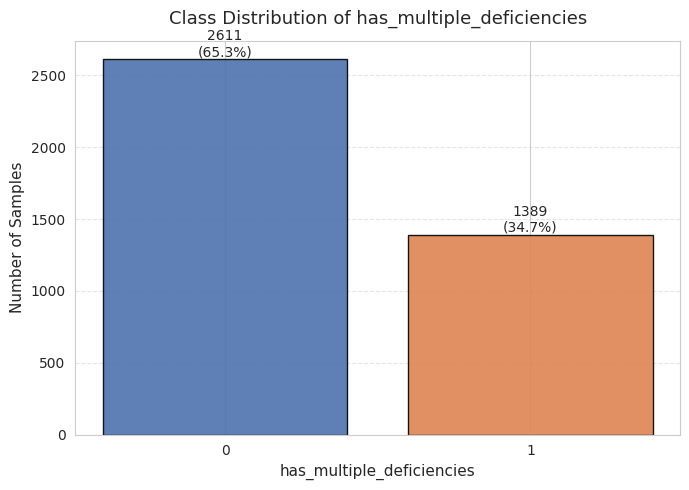

In [13]:
# Bar Chart: Class Distribution

plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_counts.index.astype(str),
    class_counts.values,
    color=['#4C72B0', '#DD8452'], 
    edgecolor='black',
    alpha=0.9
)

# Axis labels and title
plt.xlabel('has_multiple_deficiencies', fontsize=11)
plt.ylabel('Number of Samples', fontsize=11)
plt.title('Class Distribution of has_multiple_deficiencies', fontsize=13, pad=12)

# Grid for readability
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate counts and percentages
total = class_counts.sum()
for bar, count in zip(bars, class_counts.values):
    percentage = (count / total) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count}\n({percentage:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

plt.show()

## **Handling Missing and Duplicate Values**

In [14]:
# Null Value Count
print("Null Value Count")
print("=" * 60)
display(df.isnull().sum())

Null Value Count


age                             0
gender                          0
bmi                             0
smoking_status                  0
alcohol_consumption          1278
exercise_level                  0
diet_type                       0
sun_exposure                    0
income_level                    0
latitude_region                 0
vitamin_a_percent_rda           0
vitamin_c_percent_rda           0
vitamin_d_percent_rda           0
vitamin_e_percent_rda           0
vitamin_b12_percent_rda         0
folate_percent_rda              0
calcium_percent_rda             0
iron_percent_rda                0
hemoglobin_g_dl                 0
serum_vitamin_d_ng_ml           0
serum_vitamin_b12_pg_ml         0
serum_folate_ng_ml              0
symptoms_count                  0
symptoms_list                1328
has_night_blindness             0
has_fatigue                     0
has_bleeding_gums               0
has_bone_pain                   0
has_muscle_weakness             0
has_numbness_t

In [15]:
df['alcohol_consumption'].head(20)

0          NaN
1     Moderate
2        Heavy
3        Heavy
4          NaN
5     Moderate
6        Heavy
7        Heavy
8        Heavy
9     Moderate
10    Moderate
11       Heavy
12    Moderate
13         NaN
14         NaN
15    Moderate
16         NaN
17       Heavy
18       Heavy
19         NaN
Name: alcohol_consumption, dtype: object

- In `alcohol_consumption` column ,missing values (NaN) most likely indicate no alcohol consumption.
Therefore, replacing these missing values with the category 'No' to ensure consistency and avoid unnecessary data loss.

In [16]:
df['alcohol_consumption'] = (
    df['alcohol_consumption']
    .fillna('No')
)

print(df['alcohol_consumption'].value_counts(dropna=False))

alcohol_consumption
Moderate    1372
Heavy       1350
No          1278
Name: count, dtype: int64


In [17]:
print('Duplicate Columns')
print("=" * 60)
df.duplicated().sum()

Duplicate Columns


np.int64(0)

## **Unnecessary & Leakage-Prone Feature Removal**

### Columns Dropped from the Dataset

#### 1. **`symptoms_list`**

**Reason for removal:**
- High degree of missing values  
- Unstructured free-text field  
- Redundant with existing binary symptom indicator columns  
- Not required for the scope of this project  

---
#### 2. **`symptoms_count`**

**Reason for removal:**
- Aggregated from symptom flags
- Near-proxy for the target  
- Causes leakage-like inflations  

---

#### 3. **Clinical Laboratory Values**

The following laboratory measurements were removed:

- `hemoglobin_g_dl`
- `serum_vitamin_d_ng_ml`
- `serum_vitamin_b12_pg_ml`
- `serum_folate_ng_ml`

**Reason for removal:**
- Not consistently available across all samples  
- Introduce significant missingness  
- Risk of data leakage depending on collection timing  
- Outside the intended feature scope for this modeling task  

---

#### 4. **Post-Diagnosis Labels**

- `disease_diagnosis`

**Reason for removal:**
- Represents a post-outcome label  
- Not available at prediction time  
- Would cause **target leakage** if included as a feature  

---


In [18]:
columns_to_drop = [
    'symptoms_list',
    'symptoms_count',
    'hemoglobin_g_dl',
    'serum_vitamin_d_ng_ml',
    'serum_vitamin_b12_pg_ml',
    'serum_folate_ng_ml',
    'disease_diagnosis'
]

print(f"Shape before dropping columns: {df.shape}")
print("=" * 60)

df = df.drop(columns=columns_to_drop, errors='ignore')

print(f"Shape after dropping columns: {df.shape}")
print("=" * 60)

display(df.head())

Shape before dropping columns: (4000, 34)
Shape after dropping columns: (4000, 27)


,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,vitamin_a_percent_rda,vitamin_c_percent_rda,vitamin_d_percent_rda,vitamin_e_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,calcium_percent_rda,iron_percent_rda,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,has_multiple_deficiencies
0,79,Male,24.8,Former,No,Active,Vegetarian,High,High,Mid,119.1,147.3,152.88,97.5,102.5,188.9,108.3,97.4,0,0,0,0,0,0,0,0,0
1,77,Female,39.9,Former,Moderate,Light,Omnivore,Low,Low,Low,85.7,57.5,32.76,82.7,62.6,51.0,42.6,102.5,0,0,0,1,0,0,0,0,0
2,24,Male,26.4,Former,Heavy,Moderate,Omnivore,Low,High,High,48.3,152.1,94.99,169.3,136.2,116.6,136.3,86.4,1,0,0,0,0,0,0,0,0
3,69,Male,23.1,Never,Heavy,Moderate,Vegetarian,High,Low,Low,75.8,51.0,51.48,85.7,31.8,66.5,76.5,60.8,0,0,0,0,0,1,1,0,0
4,63,Male,29.6,Never,No,Moderate,Vegetarian,Moderate,High,Low,93.3,111.5,62.90,155.6,72.6,124.9,69.4,71.9,0,0,0,0,0,0,0,0,0


# **EXPLORATORY DATA ANALYSIS**

## Dataset Overview (Post-Preprocessing)

In [19]:
print(f'Shape of Dataset after preprocessing(rows,colums): {df.shape}')
print('-'*50)
print('Information of all Columns:')
print('-'*50)
df.info()

Shape of Dataset after preprocessing(rows,colums): (4000, 27)
--------------------------------------------------
Information of all Columns:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        4000 non-null   int64  
 1   gender                     4000 non-null   object 
 2   bmi                        4000 non-null   float64
 3   smoking_status             4000 non-null   object 
 4   alcohol_consumption        4000 non-null   object 
 5   exercise_level             4000 non-null   object 
 6   diet_type                  4000 non-null   object 
 7   sun_exposure               4000 non-null   object 
 8   income_level               4000 non-null   object 
 9   latitude_region            4000 non-null   object 
 10  vitamin_a_percent_rda   

In [20]:
print('Statistical Information of Dataset(Post-Preprocessing):')

print("=" * 60)
print('Numerical Columns')
print('-'*50)

display(df.describe().T)

print('-'*50)
print('Categorical Columns')
print('-'*50)

df.describe(include = 'object').T

Statistical Information of Dataset(Post-Preprocessing):
Numerical Columns
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
age,4000.0,50.766250,19.306237,18.0,34.000,51.00,67.0000,84.0
bmi,4000.0,26.105325,4.922746,15.0,22.800,26.20,29.4000,45.0
vitamin_a_percent_rda,4000.0,90.770850,37.083534,10.0,62.600,85.50,115.3000,219.0
vitamin_c_percent_rda,4000.0,89.199075,37.505809,10.0,60.975,83.50,113.0000,250.0
vitamin_d_percent_rda,4000.0,72.216388,42.831000,7.0,40.730,62.27,93.3175,275.6
vitamin_e_percent_rda,4000.0,89.946125,37.444649,10.0,61.700,84.05,114.1000,237.6
vitamin_b12_percent_rda,4000.0,62.743225,37.396636,10.0,32.700,55.60,84.5000,243.6
folate_percent_rda,4000.0,90.382275,37.563684,10.0,61.800,84.80,115.2000,226.6
calcium_percent_rda,4000.0,82.586300,36.359131,10.0,55.600,77.10,105.3000,232.7
iron_percent_rda,4000.0,76.211125,33.226984,10.0,51.400,71.25,95.9000,211.4


--------------------------------------------------
Categorical Columns
--------------------------------------------------


,count,unique,top,freq
gender,4000,2,Male,2029
smoking_status,4000,3,Never,1344
alcohol_consumption,4000,3,Moderate,1372
exercise_level,4000,4,Sedentary,1033
diet_type,4000,4,Vegan,1017
sun_exposure,4000,3,Moderate,1357
income_level,4000,3,High,1362
latitude_region,4000,3,Low,1358
has_night_blindness,4000,2,0,3591
has_fatigue,4000,2,0,2923


## **Univariate Analysis**

### **Numerical Features**

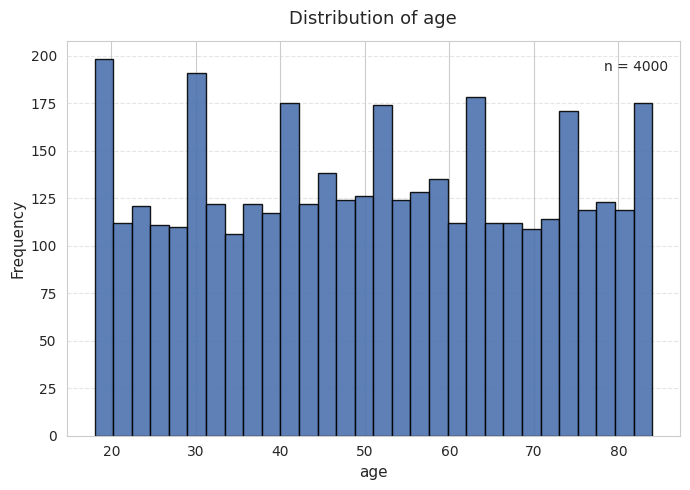

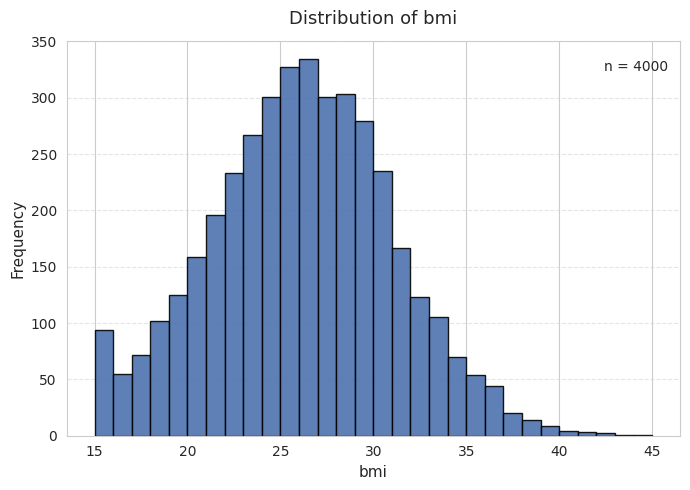

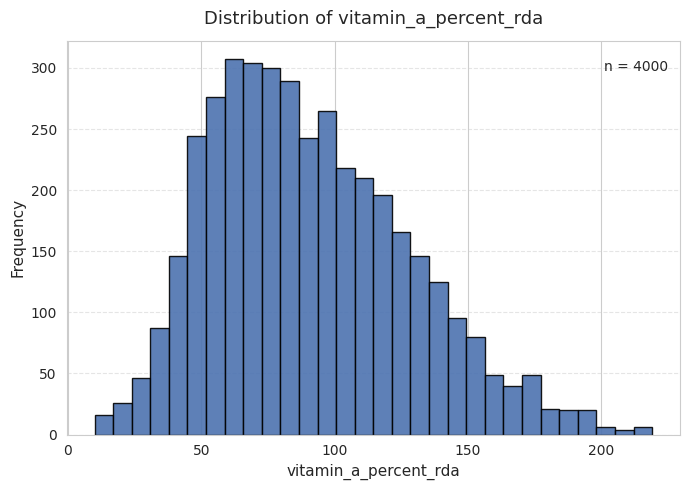

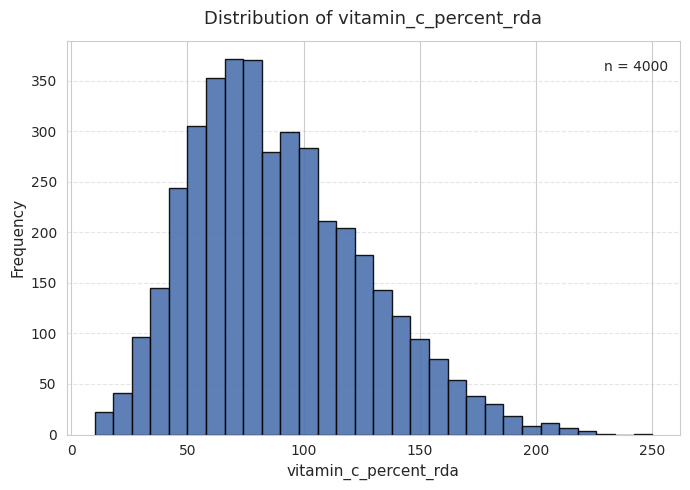

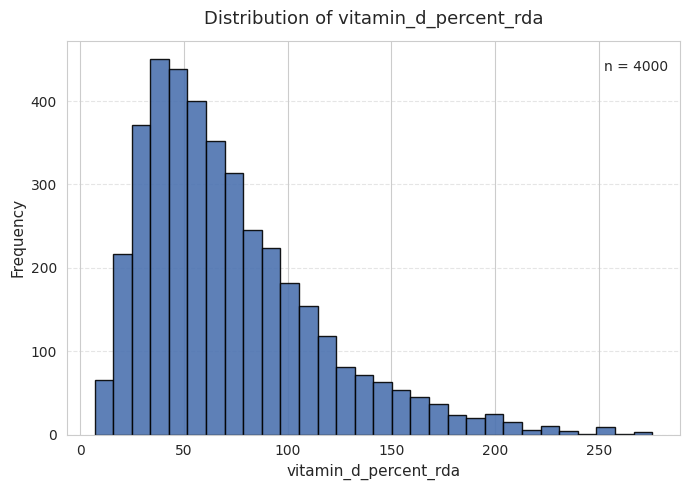

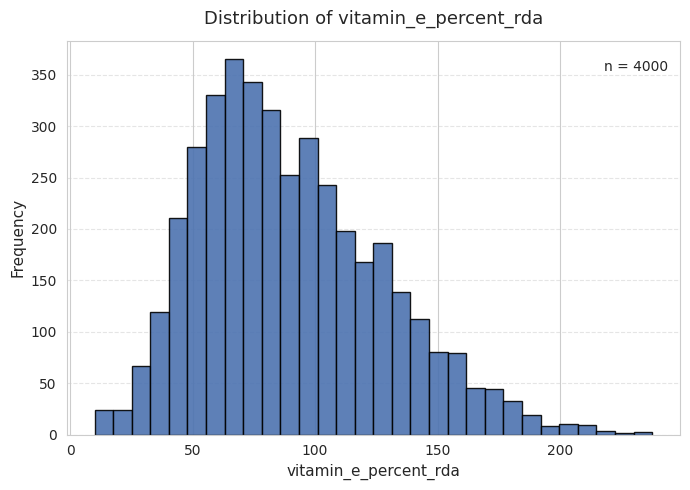

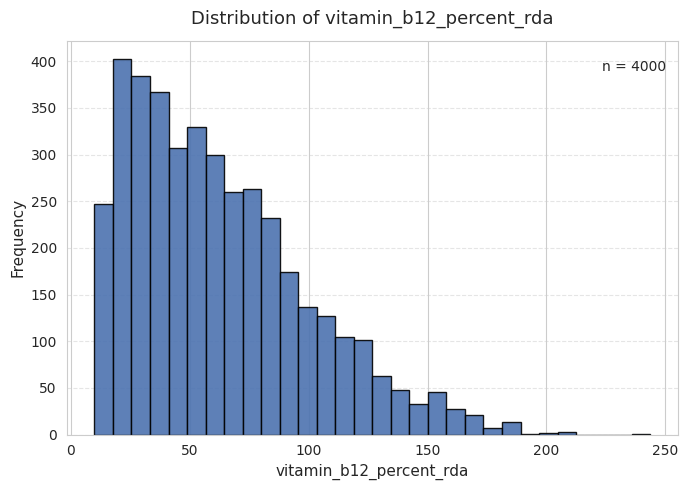

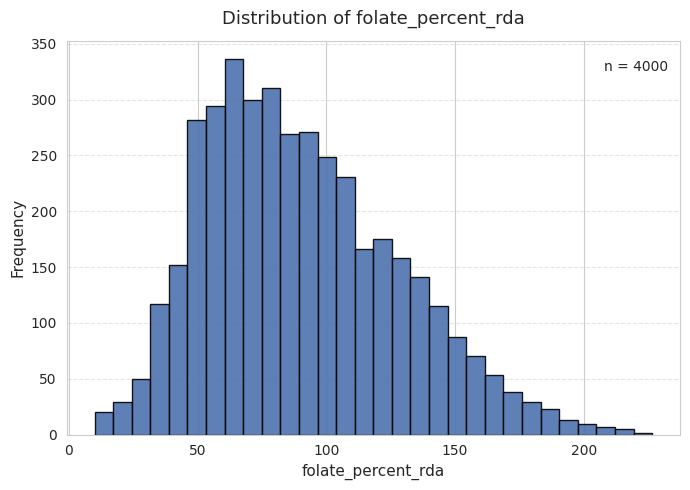

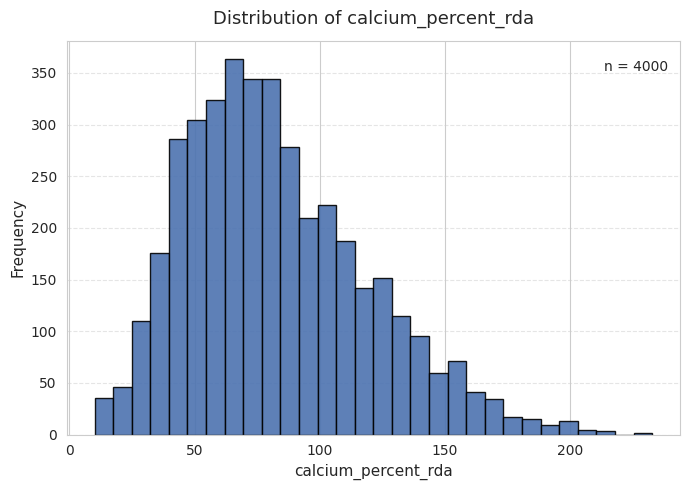

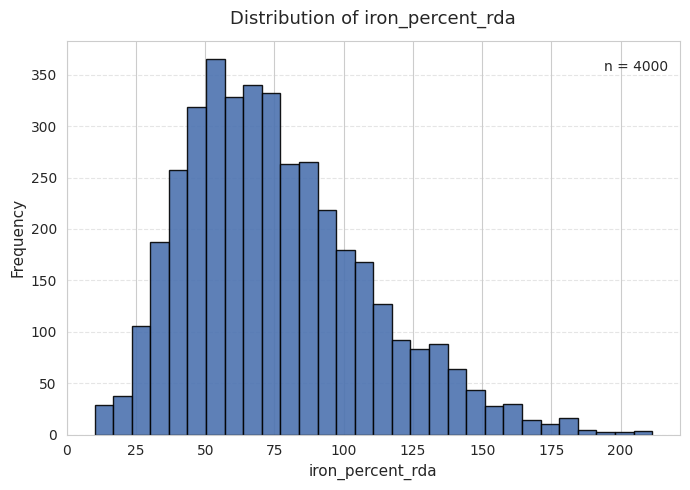

In [21]:
# list of numerical features for univariate analysis
num_features = df.select_dtypes(include='number').columns

for col in num_features:
    data = df[col].dropna()

    plt.figure(figsize=(7, 5))

    counts, bins, patches = plt.hist(
        data,
        bins=30,
        color='#4C72B0',        
        edgecolor='black',
        alpha=0.9
    )

    # Axis labels and title
    plt.xlabel(col, fontsize=11)
    plt.ylabel("Frequency", fontsize=11)
    plt.title(f"Distribution of {col}", fontsize=13, pad=12)

    plt.grid(axis='y', linestyle='--', alpha=0.5)

    plt.text(
        0.98, 0.95,
        f'n = {len(data)}',
        transform=plt.gca().transAxes,
        ha='right',
        va='top',
        fontsize=10
    )

    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)

    plt.tight_layout()
    plt.show()

- Age exhibits an approximately uniform distribution across the adult lifespan, with minor spikes at specific values likely due to discretization or sampling artifacts. No strong skewness is observed, and no transformation is required.
- BMI exhibits an approximately normal distribution with a mild right tail, consistent with population-level body mass patterns. No transformation is required.
- Most vitamin and minerals variables are right-skewed, reflecting low-to-moderate intake in the majority of individuals and higher intake in a smaller subset.
- Symptoms count shows a heavily right-skewed distribution, with most individuals reporting few or no symptoms. 



### **Categorical Features**

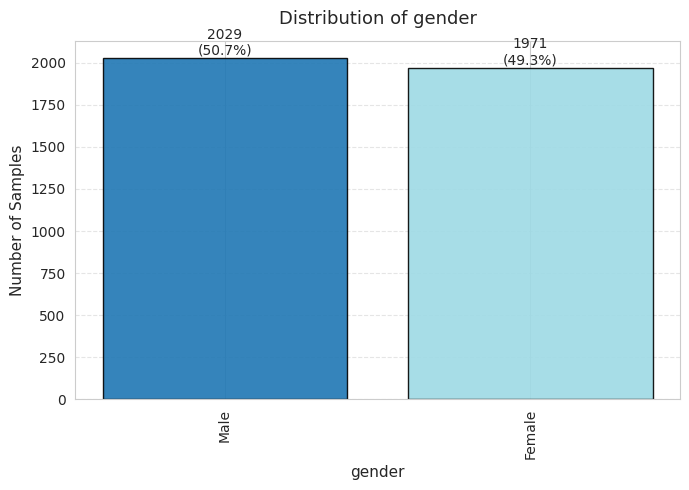

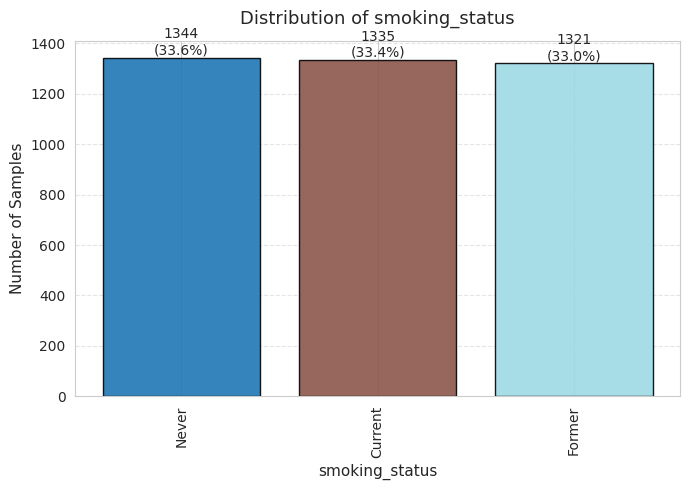

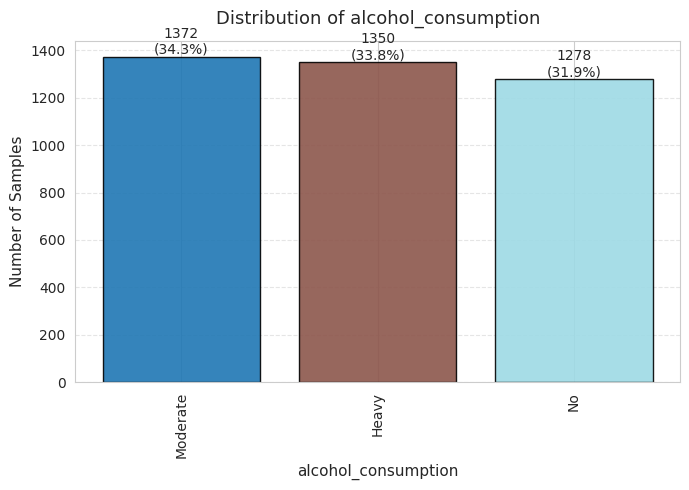

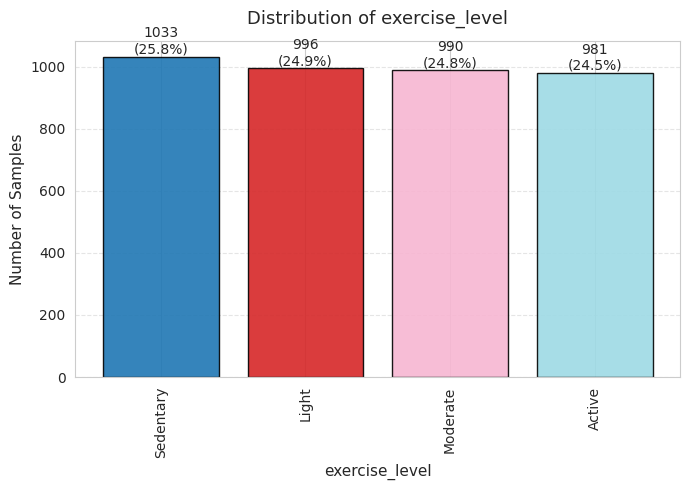

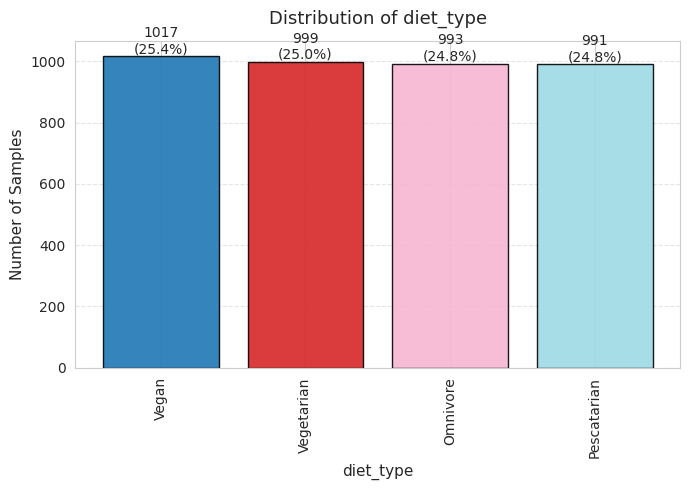

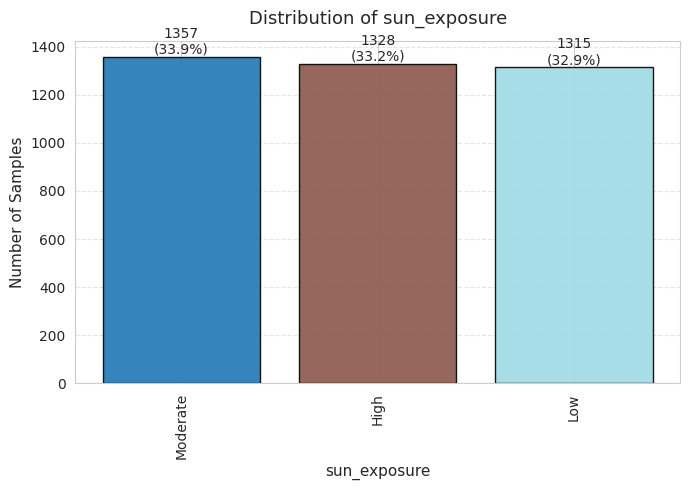

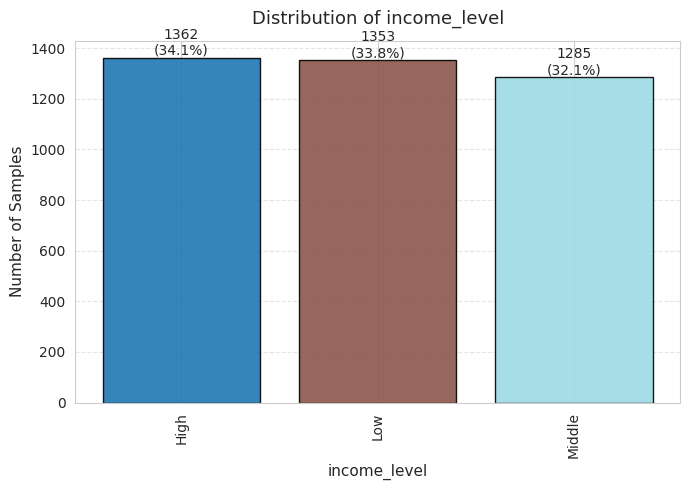

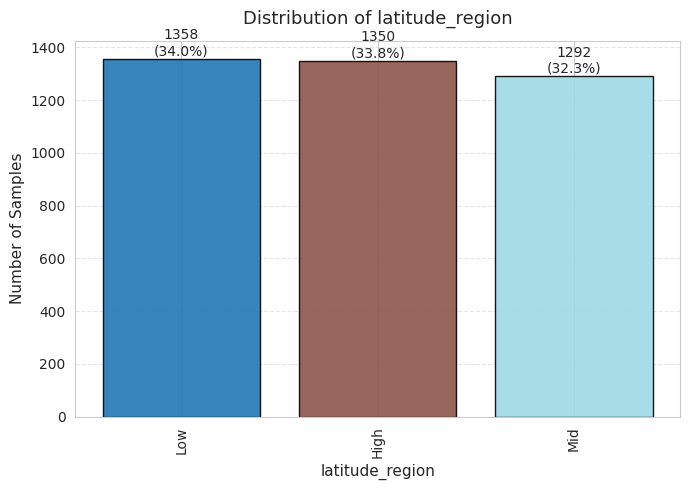

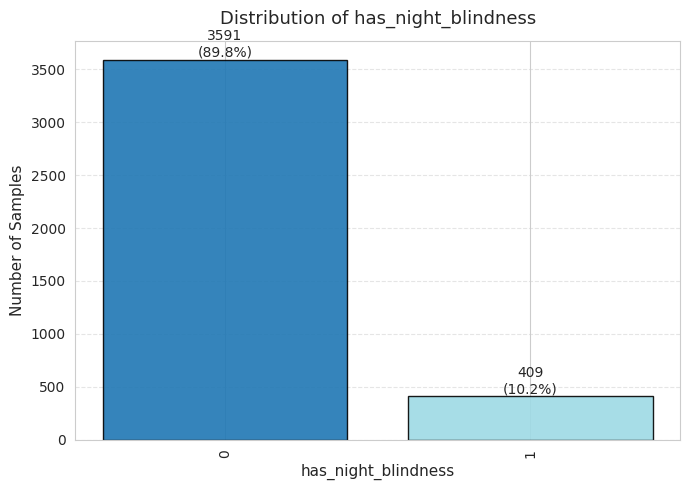

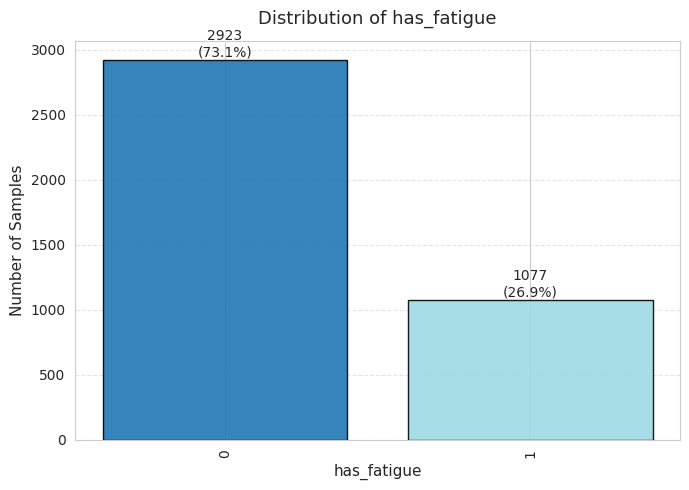

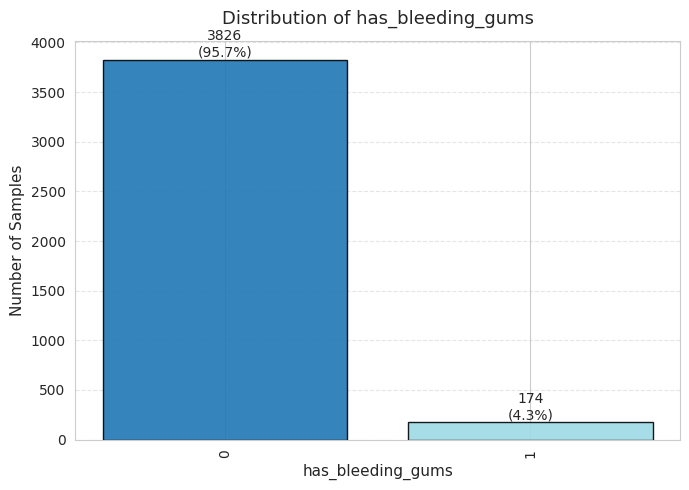

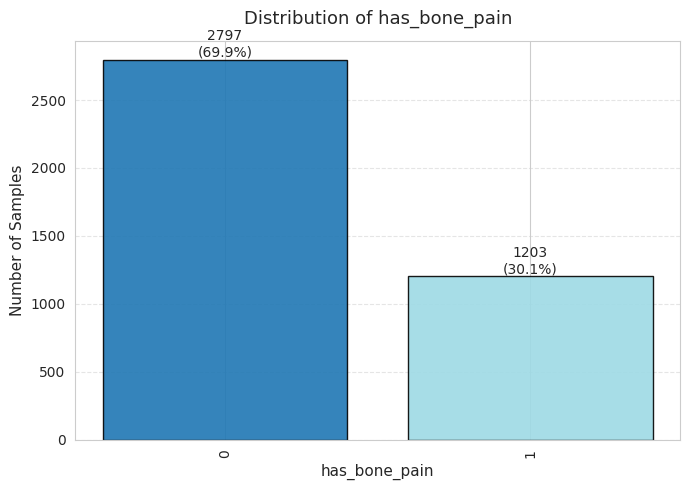

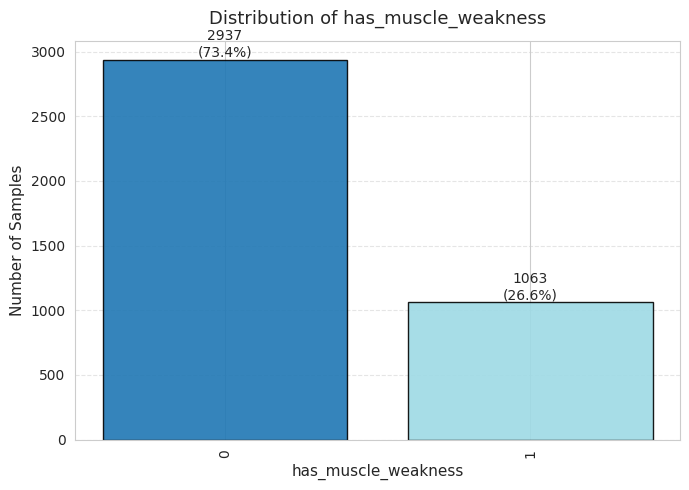

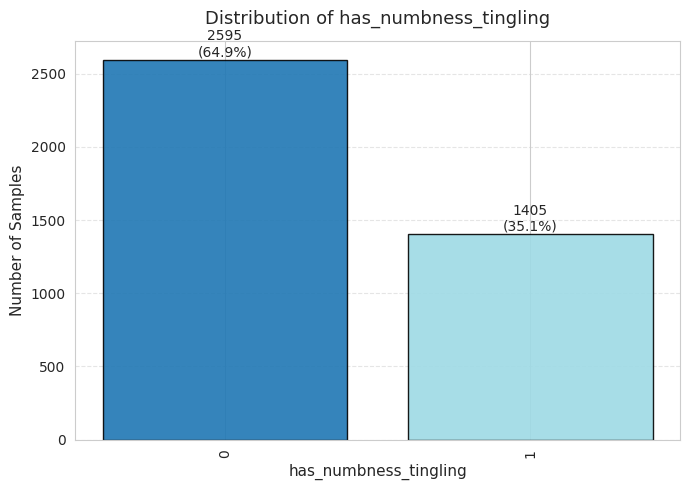

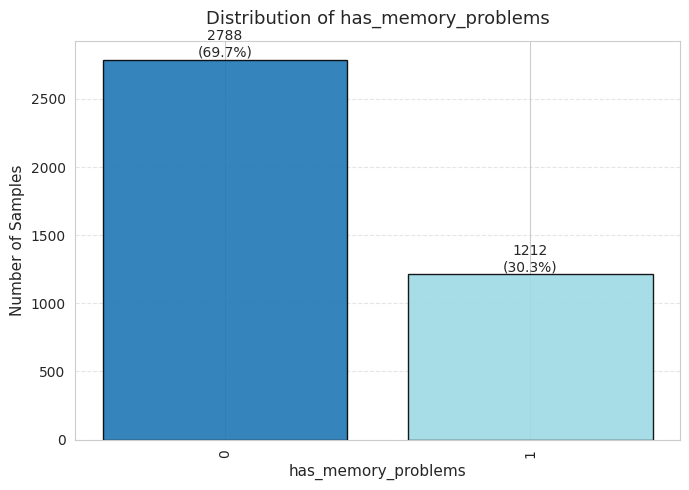

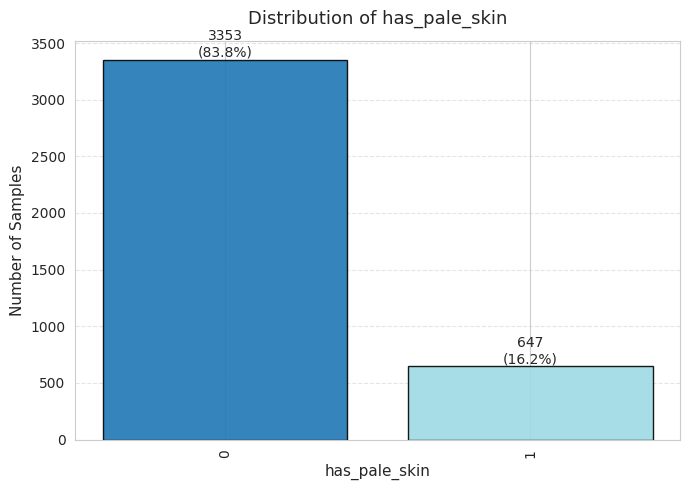

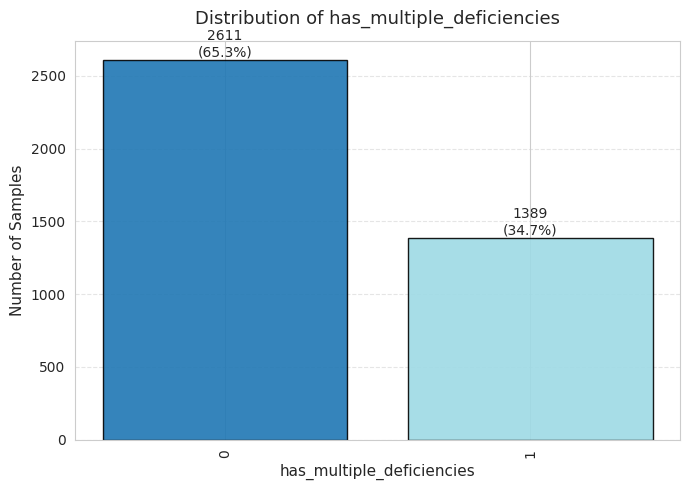

In [22]:
# categorical features for univariate analysis
cat_features = df.select_dtypes(include='object').columns

for col in cat_features:
    # value counts
    value_counts = df[col].value_counts()
    total = value_counts.sum()

    plt.figure(figsize=(7, 5))

    # generate distinct colors
    colors = plt.cm.tab20(np.linspace(0, 1, len(value_counts)))

    # bar chart
    bars = plt.bar(
        value_counts.index.astype(str),
        value_counts.values,
        color=colors,
        edgecolor='black',
        alpha=0.9
    )

    # labels and title
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Number of Samples', fontsize=11)
    plt.title(f'Distribution of {col}', fontsize=13, pad=12)

    # grid
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # annotations
    for bar, count in zip(bars, value_counts.values):
        percentage = (count / total) * 100
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f'{count}\n({percentage:.1f}%)',
            ha='center',
            va='bottom',
            fontsize=10
        )

    plt.xticks(rotation=90, fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()


## **Bivariate Analysis**

### **Target vs Numerical Features**

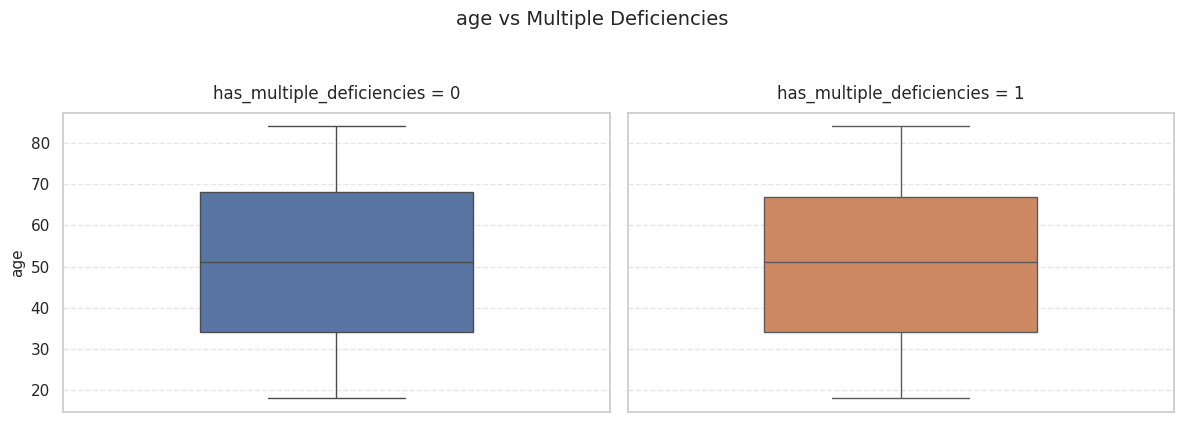

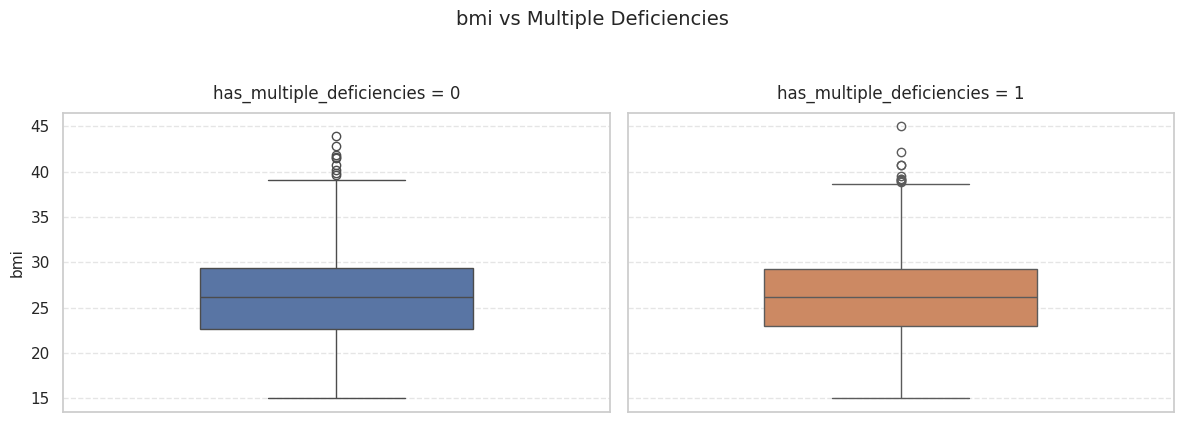

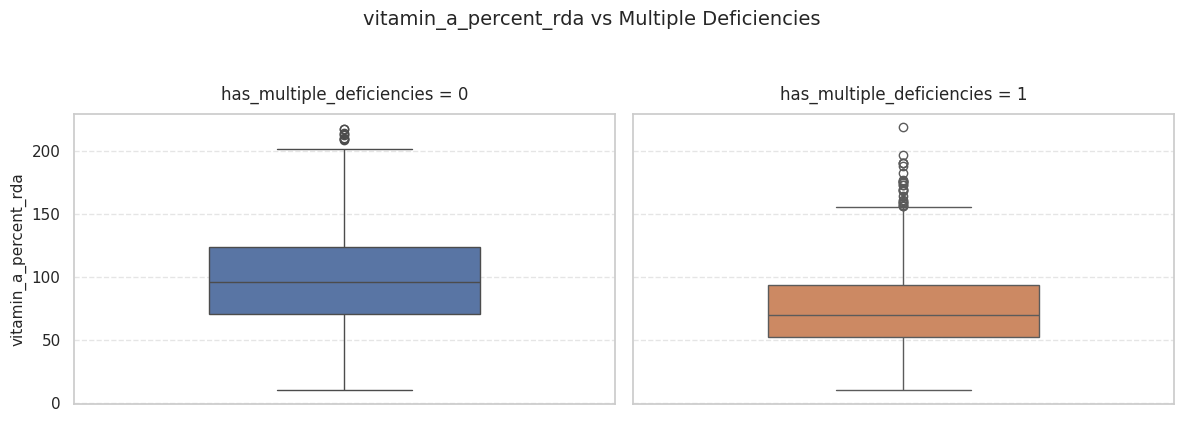

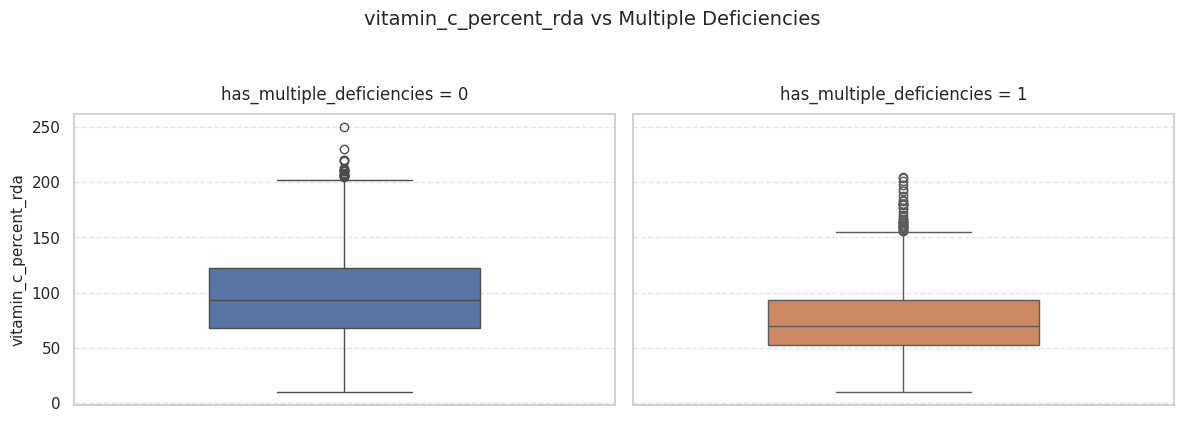

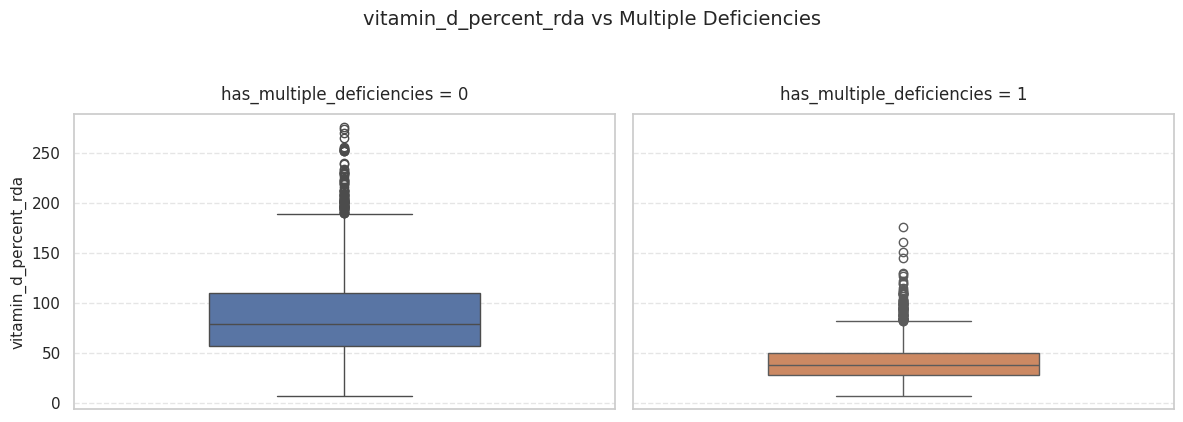

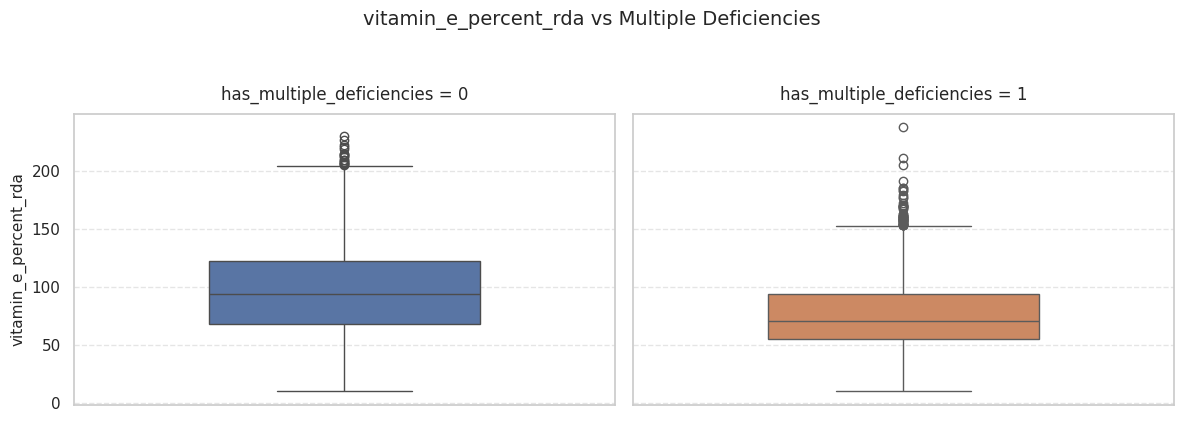

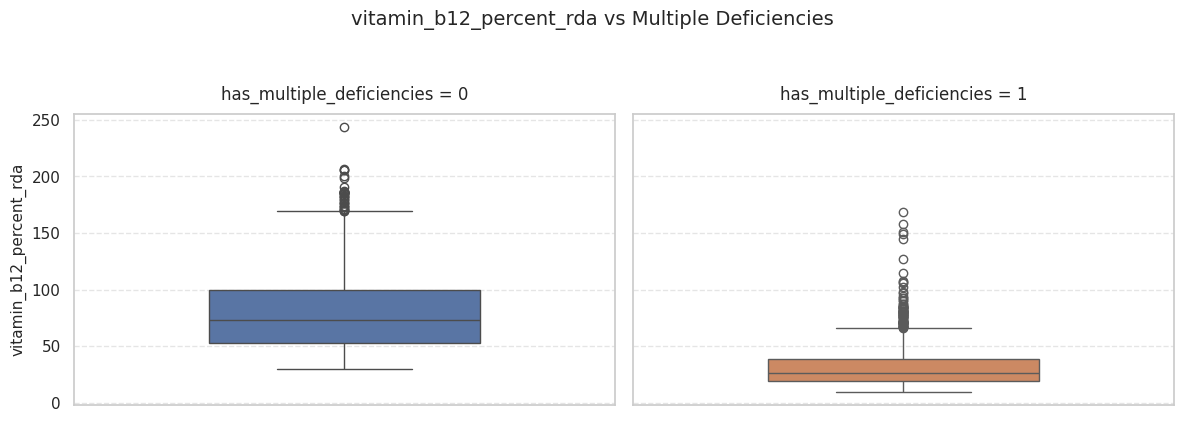

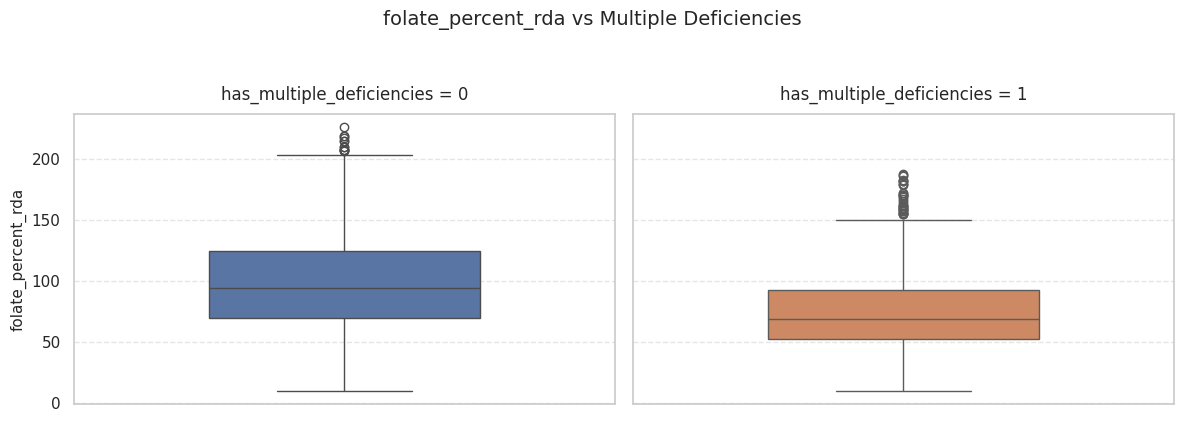

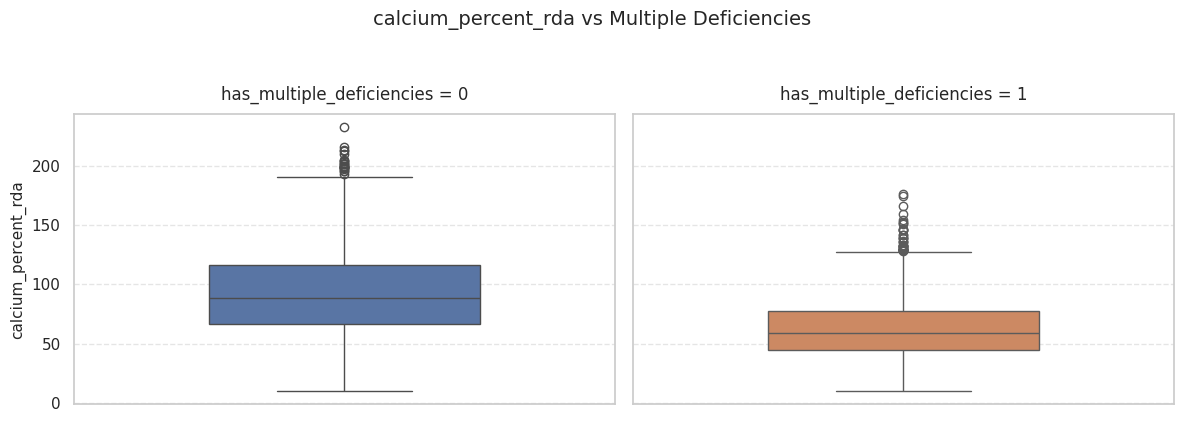

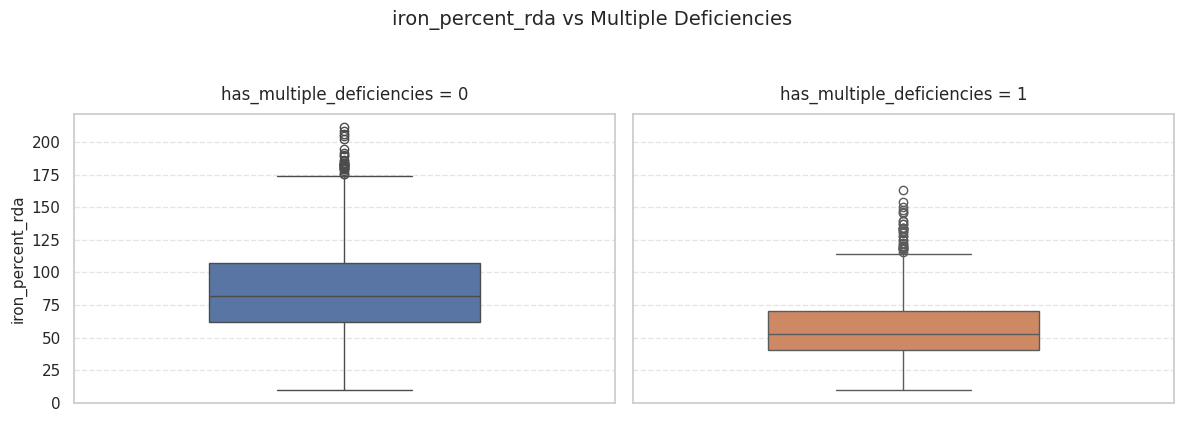

In [23]:
sns.set(style="whitegrid")

num_features = num_features  
target = "has_multiple_deficiencies"

palette = ['#4C72B0', '#DD8452']

for col in num_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    for i, class_value in enumerate(sorted(df[target].unique())):
        sns.boxplot(
            data=df[df[target] == class_value],
            y=col,
            ax=axes[i],
            color=palette[i],
            width=0.5
        )

        axes[i].set_title(
            f"{target} = {class_value}",
            fontsize=12,
            pad=10
        )
        axes[i].set_xlabel("")
        axes[i].grid(axis='y', linestyle='--', alpha=0.5)

    # shared labels
    axes[0].set_ylabel(col, fontsize=11)
    fig.suptitle(f"{col} vs Multiple Deficiencies", fontsize=14, y=1.05)

    plt.tight_layout()
    plt.show()


- Vitamin and mineral intake variables show clear separation between classes, with consistently lower median intake among individuals with multiple deficiencies.
- The strongest associations are observed for vitamin D, vitamin B12, iron, and calcium.
- Age and BMI display substantial overlap between classes, indicating limited standalone predictive power.
- Overall, nutritional intake features provide the strongest signal for predicting multiple micronutrient deficiencies.

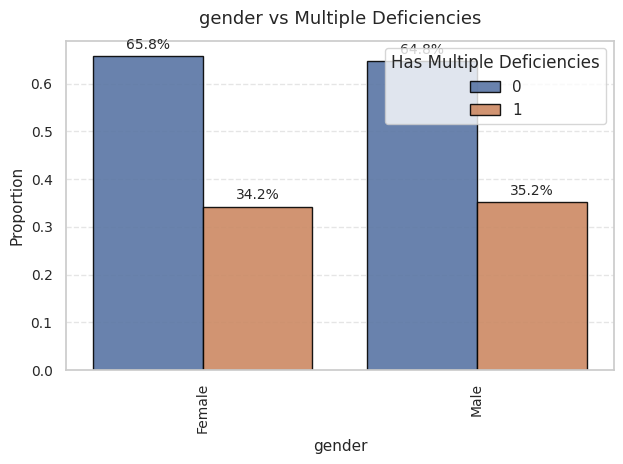

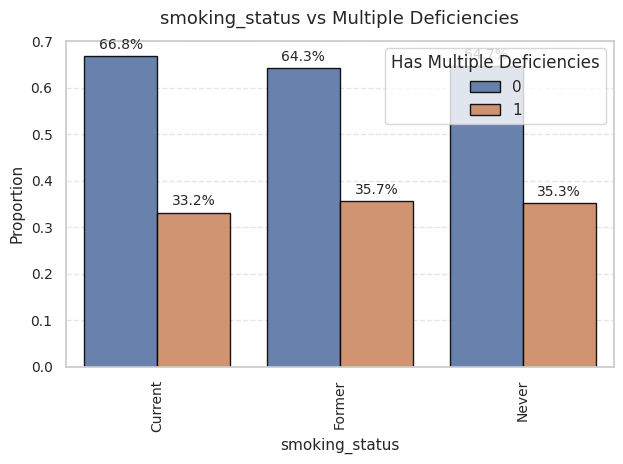

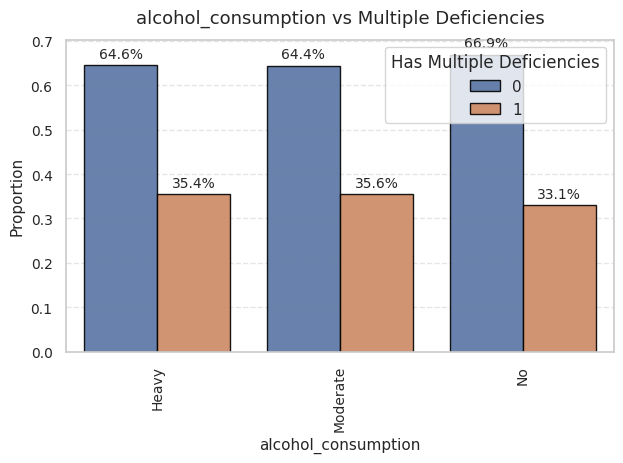

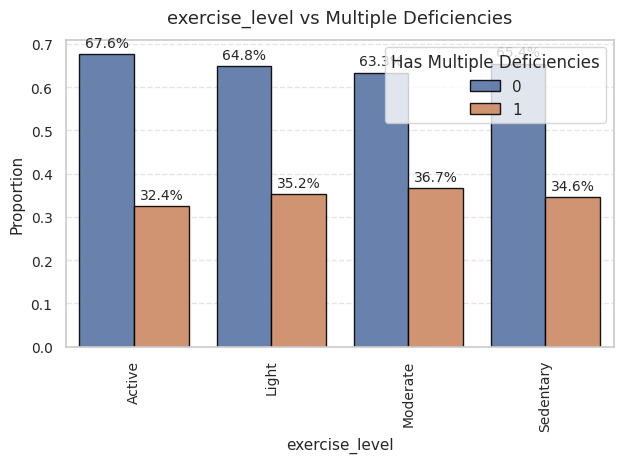

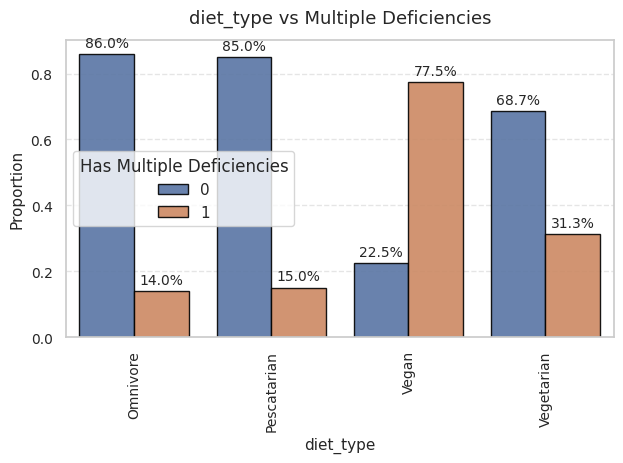

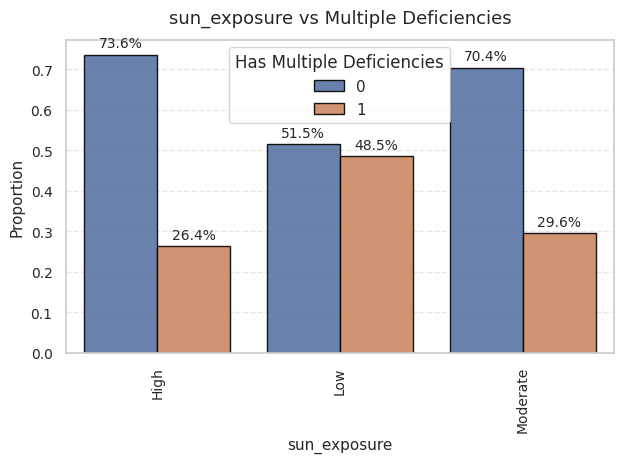

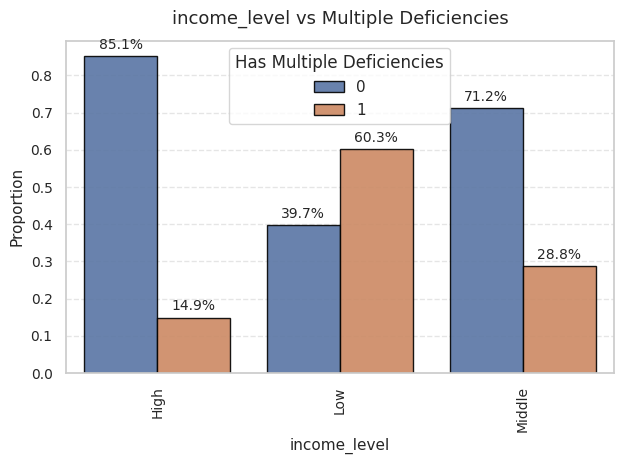

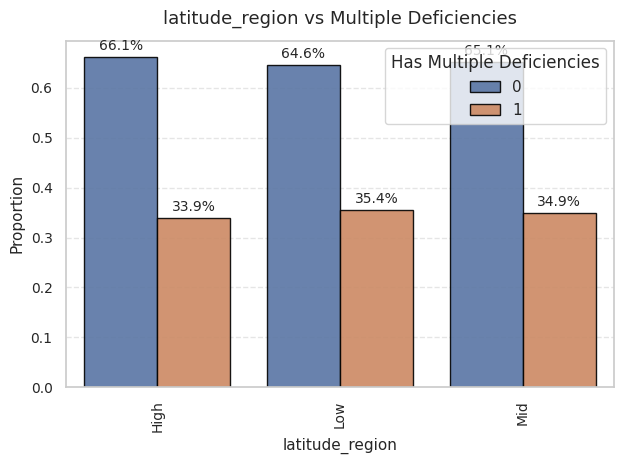

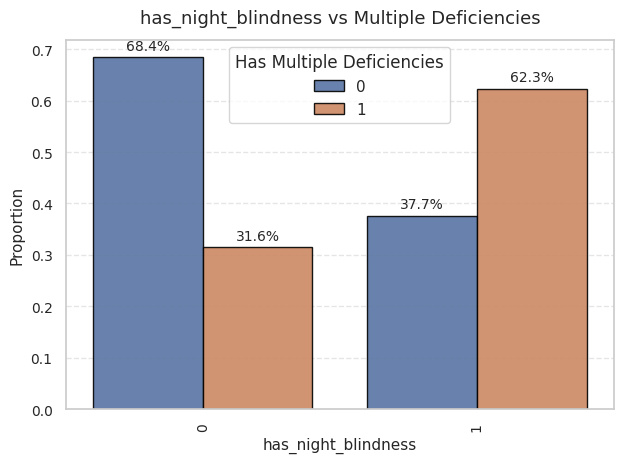

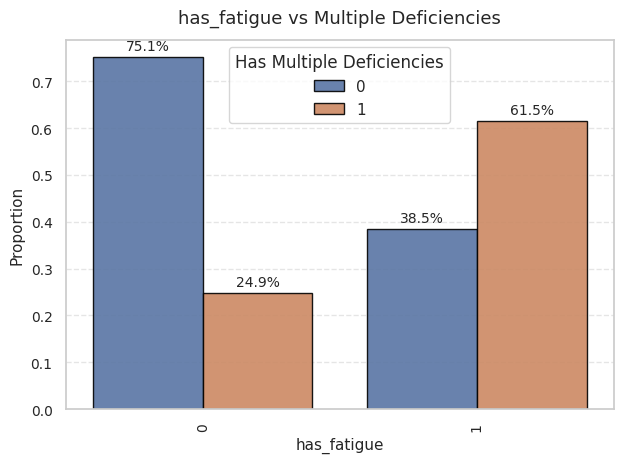

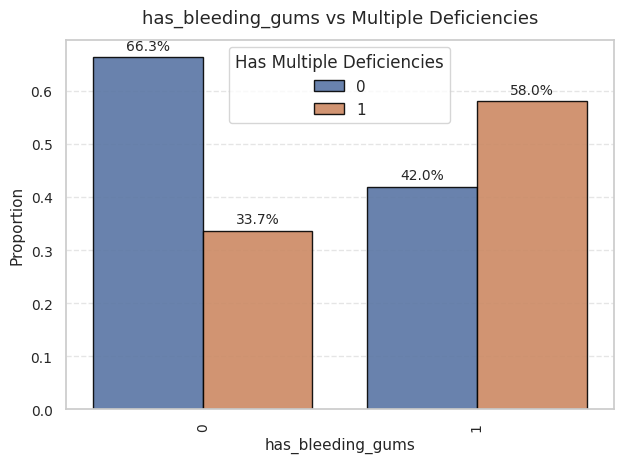

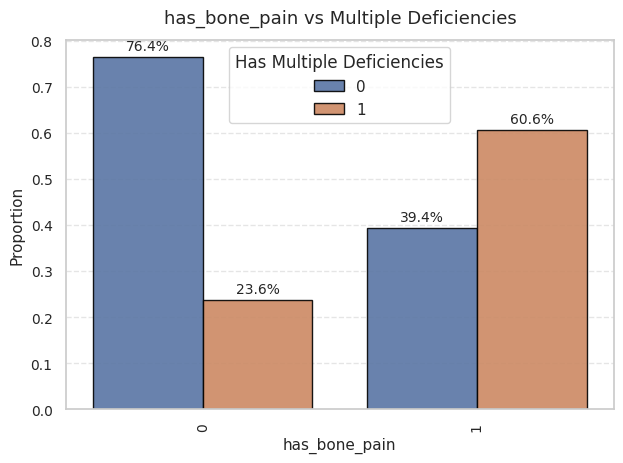

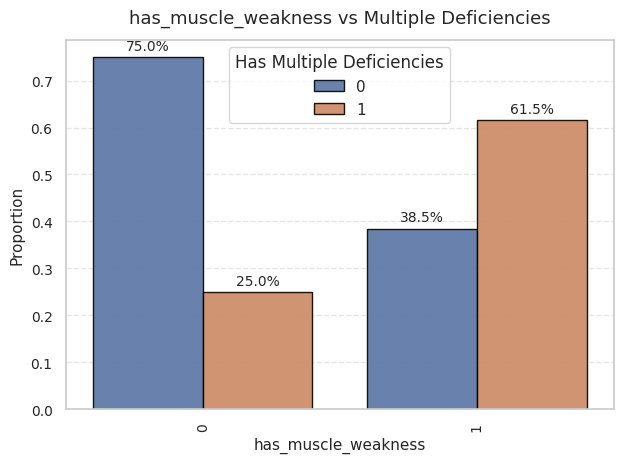

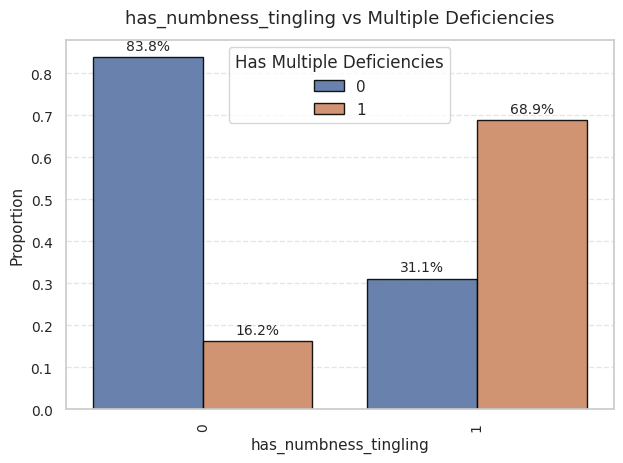

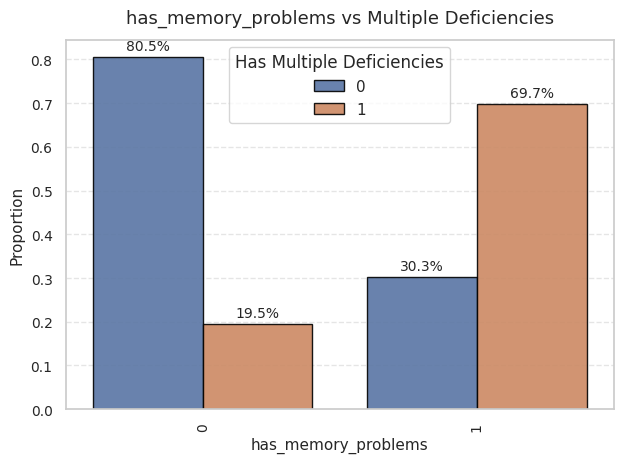

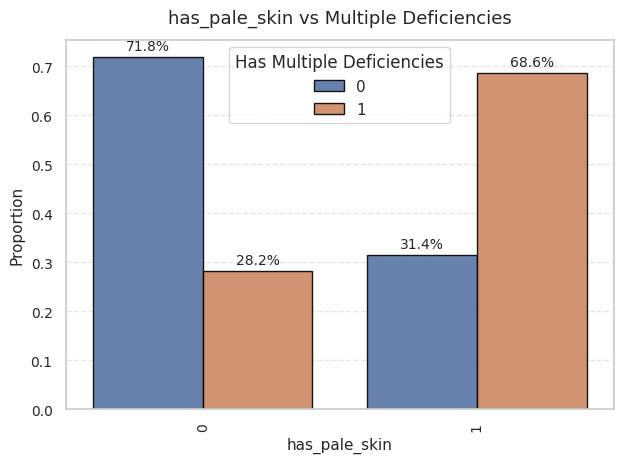

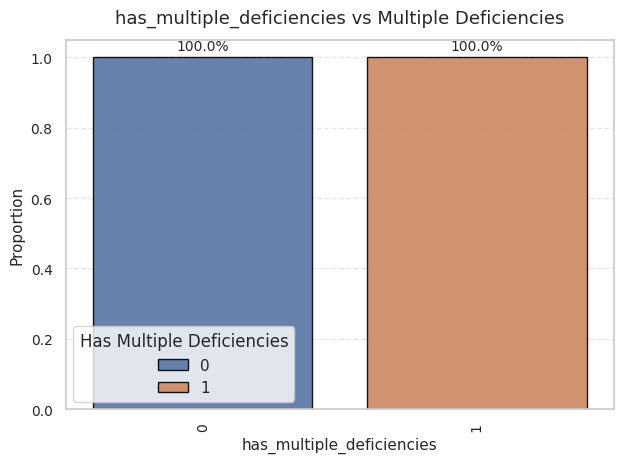

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

palette = ['#4C72B0', '#DD8452']  # class 0, class 1

for col in cat_features:
    # plt.figure(figsize=(4, 3))

    # proportion table
    prop_df = (
        df.groupby(col)["has_multiple_deficiencies"]
        .value_counts(normalize=True)
        .rename("proportion")
        .reset_index()
    )

    ax = sns.barplot(
        data=prop_df,
        x=col,
        y="proportion",
        hue="has_multiple_deficiencies",
        palette=palette,
        edgecolor='black',
        alpha=0.9
    )

    # annotations
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[f"{v * 100:.1f}%" for v in container.datavalues],
            label_type='edge',
            fontsize=10,
            padding=3
        )

    # labels and title
    plt.title(f"{col} vs Multiple Deficiencies", fontsize=13, pad=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel("Proportion", fontsize=11)

    # grid
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    plt.xticks(rotation=90, fontsize=10)
    plt.yticks(fontsize=10)

    plt.legend(title="Has Multiple Deficiencies")
    plt.tight_layout()
    plt.show()


- Gender, smoking status, alcohol consumption, exercise level, and latitude region largely follow the overall class distribution (~65% non-deficient, ~35% deficient), indicating weak standalone predictive power.
- Diet type shows a strong association with multiple deficiencies, with vegan and vegetarian diets exhibiting substantially higher deficiency prevalence compared to omnivorous and pescatarian diets.
- Income level demonstrates a clear socioeconomic gradient, where lower income groups have a significantly higher likelihood of multiple micronutrient deficiencies.
- Sun exposure exhibits a meaningful relationship, with low sun exposure associated with increased deficiency risk.
- Binary symptom indicators (night blindness, fatigue, bleeding gums, bone pain, muscle weakness, numbness/tingling, memory problems, and pale skin) show strong separation, with symptomatic individuals being much more likely to have multiple deficiencies.
- Overall, lifestyle and demographic variables contribute moderate signal, while diet type, income level, sun exposure, and symptom indicators emerge as the most informative categorical predictors.

# FEATURE ENGINEERING

## Encoding Ordinal features

In [25]:
print(df["sun_exposure"].value_counts())
print("=" * 60)
print(df["exercise_level"].value_counts())
print("=" * 60)
print(df["income_level"].value_counts())

sun_exposure
Moderate    1357
High        1328
Low         1315
Name: count, dtype: int64
exercise_level
Sedentary    1033
Light         996
Moderate      990
Active        981
Name: count, dtype: int64
income_level
High      1362
Low       1353
Middle    1285
Name: count, dtype: int64


In [26]:
ordinal_features = ["sun_exposure", "exercise_level", "income_level"]

for col in ordinal_features:
    df[col] = (
        df[col]
        .astype(str)
        .str.lower()
        .str.strip()
    )
ordinal_categories = [
    ["low", "moderate", "high"],                # sun_exposure
    ["sedentary", "light", "moderate", "active"],  # exercise_level
    ["low", "middle", "high"]                   # income_level
]

In [27]:
ordinal_encoder = OrdinalEncoder(
    categories=ordinal_categories,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

df[ordinal_features] = ordinal_encoder.fit_transform(df[ordinal_features])


In [28]:
(df[ordinal_features] == -1).mean()

sun_exposure      0.0
exercise_level    0.0
income_level      0.0
dtype: float64

In [29]:
print(f'Shape of Dataset(rows,colums): {df.shape}')

Shape of Dataset(rows,colums): (4000, 27)


## Nutritional Risk Feature Creation

In [30]:
# # Nutrient intake columns (%RDA)
# vitamin_cols = [
#     "vitamin_a_percent_rda",
#     "vitamin_c_percent_rda",
#     "vitamin_d_percent_rda",
#     "vitamin_e_percent_rda",
#     "vitamin_b12_percent_rda",
#     "folate_percent_rda",
#     "calcium_percent_rda",
#     "iron_percent_rda"
# ]

# # Low intake indicator flags (domain-informed thresholds)
# df["vitamin_d_low"]   = (df["vitamin_d_percent_rda"] < 50).astype(int)
# df["vitamin_b12_low"] = (df["vitamin_b12_percent_rda"] < 70).astype(int)
# df["iron_low"]        = (df["iron_percent_rda"] < 70).astype(int)
# df["calcium_low"]     = (df["calcium_percent_rda"] < 70).astype(int)
# df["folate_low"]      = (df["folate_percent_rda"] < 70).astype(int)

In [31]:
# # Average intake across all nutrients
# df["avg_vitamin_rda"] = df[vitamin_cols].mean(axis=1)

# # Minimum intake across all nutrients
# df["min_vitamin_rda"] = df[vitamin_cols].min(axis=1)

# # Count of low-intake nutrients
# low_flag_cols = [
#     "vitamin_d_low",
#     "vitamin_b12_low",
#     "iron_low",
#     "calcium_low",
#     "folate_low"
# ]

# df["num_low_nutrients"] = df[low_flag_cols].sum(axis=1)

In [32]:
# # Interaction between sun exposure and vitamin D intake
# df["sun_vitamin_d_interaction"] = (
#     df["sun_exposure"] * df["vitamin_d_percent_rda"]
# )

In [33]:
# # Check missing values in engineered features
# engineered_features = (
#     low_flag_cols +
#     ["avg_vitamin_rda", "min_vitamin_rda", "num_low_nutrients",
#      "sun_vitamin_d_interaction"]
# )

# df[engineered_features].isnull().sum()

In [34]:
print( "First 5 rows")
print("=" * 60)
display(df.head())

print("=" * 60)

print( "Last 5 rows")
print("=" * 60)
display(df.tail())
print("=" * 60)
print(f'Shape of Dataset(rows,colums): {df.shape}')

First 5 rows


,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,vitamin_a_percent_rda,vitamin_c_percent_rda,vitamin_d_percent_rda,vitamin_e_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,calcium_percent_rda,iron_percent_rda,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,has_multiple_deficiencies
0,79,Male,24.8,Former,No,3.0,Vegetarian,2.0,2.0,Mid,119.1,147.3,152.88,97.5,102.5,188.9,108.3,97.4,0,0,0,0,0,0,0,0,0
1,77,Female,39.9,Former,Moderate,1.0,Omnivore,0.0,0.0,Low,85.7,57.5,32.76,82.7,62.6,51.0,42.6,102.5,0,0,0,1,0,0,0,0,0
2,24,Male,26.4,Former,Heavy,2.0,Omnivore,0.0,2.0,High,48.3,152.1,94.99,169.3,136.2,116.6,136.3,86.4,1,0,0,0,0,0,0,0,0
3,69,Male,23.1,Never,Heavy,2.0,Vegetarian,2.0,0.0,Low,75.8,51.0,51.48,85.7,31.8,66.5,76.5,60.8,0,0,0,0,0,1,1,0,0
4,63,Male,29.6,Never,No,2.0,Vegetarian,1.0,2.0,Low,93.3,111.5,62.90,155.6,72.6,124.9,69.4,71.9,0,0,0,0,0,0,0,0,0


Last 5 rows


,age,gender,bmi,smoking_status,alcohol_consumption,exercise_level,diet_type,sun_exposure,income_level,latitude_region,vitamin_a_percent_rda,vitamin_c_percent_rda,vitamin_d_percent_rda,vitamin_e_percent_rda,vitamin_b12_percent_rda,folate_percent_rda,calcium_percent_rda,iron_percent_rda,has_night_blindness,has_fatigue,has_bleeding_gums,has_bone_pain,has_muscle_weakness,has_numbness_tingling,has_memory_problems,has_pale_skin,has_multiple_deficiencies
3995,25,Female,21.6,Former,Heavy,3.0,Pescatarian,1.0,1.0,High,41.4,66.1,111.50,99.8,72.8,77.0,142.0,72.9,1,0,0,0,0,0,0,0,0
3996,50,Male,29.5,Former,Moderate,0.0,Vegetarian,0.0,2.0,Low,146.3,113.0,72.66,91.5,99.4,120.1,101.4,94.1,0,0,0,0,0,0,0,0,0
3997,34,Female,24.8,Never,No,3.0,Pescatarian,1.0,0.0,Low,77.0,39.8,76.10,43.2,41.6,62.7,43.9,53.7,0,1,0,0,0,1,1,0,0
3998,39,Female,26.9,Former,Heavy,3.0,Omnivore,2.0,0.0,High,41.1,71.2,75.79,32.5,53.4,47.3,15.4,56.3,1,0,0,0,0,0,0,0,0
3999,41,Female,28.0,Current,No,0.0,Omnivore,2.0,2.0,High,135.6,63.7,155.61,170.0,38.8,127.7,130.9,130.5,0,0,0,0,0,0,1,0,0


Shape of Dataset(rows,colums): (4000, 27)


# MODEL TRAINING

In [35]:
num_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = df.select_dtypes(include=["object"]).columns.tolist()

print('num_features: ',num_features)
print("=" * 60)
print('cat_features:', cat_features)

num_features:  ['age', 'bmi', 'exercise_level', 'sun_exposure', 'income_level', 'vitamin_a_percent_rda', 'vitamin_c_percent_rda', 'vitamin_d_percent_rda', 'vitamin_e_percent_rda', 'vitamin_b12_percent_rda', 'folate_percent_rda', 'calcium_percent_rda', 'iron_percent_rda']
cat_features: ['gender', 'smoking_status', 'alcohol_consumption', 'diet_type', 'latitude_region', 'has_night_blindness', 'has_fatigue', 'has_bleeding_gums', 'has_bone_pain', 'has_muscle_weakness', 'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin', 'has_multiple_deficiencies']


- only `gender`, `smoking_status`,`alcohol_consumption`,`diet_type`,`latitude_region` needs to be one-hot-encoded.
- rest categorical features are binary. we earlier converted them in *object* dtpye. Now we will convert them back to *numeric*

In [36]:
binary_obj_cols = [
    col for col in df.columns
    if df[col].dtype == "object"
    and set(df[col].dropna().unique()).issubset(
        {"0", "1", 0, 1, True, False}
    )
]

binary_obj_cols

['has_night_blindness',
 'has_fatigue',
 'has_bleeding_gums',
 'has_bone_pain',
 'has_muscle_weakness',
 'has_numbness_tingling',
 'has_memory_problems',
 'has_pale_skin',
 'has_multiple_deficiencies']

In [37]:
# force correct numeric conversion
for col in binary_obj_cols:
    df[col] = (
        df[col]
        .replace({"0": 0, "1": 1, True: 1, False: 0})
        .astype("int64")
    )

In [38]:
X = df.drop(columns=["has_multiple_deficiencies"])
y = df["has_multiple_deficiencies"]
num_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = X.select_dtypes(include=["object"]).columns.tolist()

print('num_features: ',num_features)
print("=" * 60)
print('cat_features:', cat_features)

num_features:  ['age', 'bmi', 'exercise_level', 'sun_exposure', 'income_level', 'vitamin_a_percent_rda', 'vitamin_c_percent_rda', 'vitamin_d_percent_rda', 'vitamin_e_percent_rda', 'vitamin_b12_percent_rda', 'folate_percent_rda', 'calcium_percent_rda', 'iron_percent_rda', 'has_night_blindness', 'has_fatigue', 'has_bleeding_gums', 'has_bone_pain', 'has_muscle_weakness', 'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin']
cat_features: ['gender', 'smoking_status', 'alcohol_consumption', 'diet_type', 'latitude_region']


## Train Test Split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [40]:
X_train.shape,X_test.shape

((3200, 26), (800, 26))

In [41]:
# numerical features (includes ordinal + binary + engineered)
num_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

# nominal categorical features (to be one-hot encoded)
cat_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:", num_features)
print("=" * 60)
print("Categorical features:", cat_features)


Numerical features: ['age', 'bmi', 'exercise_level', 'sun_exposure', 'income_level', 'vitamin_a_percent_rda', 'vitamin_c_percent_rda', 'vitamin_d_percent_rda', 'vitamin_e_percent_rda', 'vitamin_b12_percent_rda', 'folate_percent_rda', 'calcium_percent_rda', 'iron_percent_rda', 'has_night_blindness', 'has_fatigue', 'has_bleeding_gums', 'has_bone_pain', 'has_muscle_weakness', 'has_numbness_tingling', 'has_memory_problems', 'has_pale_skin']
Categorical features: ['gender', 'smoking_status', 'alcohol_consumption', 'diet_type', 'latitude_region']


## Preprocessor Pipeline(Scaling + One-Hot Encoding)

In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), cat_features)
    ],
    remainder="drop"
)

## Logistic Regression

In [43]:
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [44]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi',
                                                   'exercise_level',
                                                   'sun_exposure',
                                                   'income_level',
                                                   'vitamin_a_percent_rda',
                                                   'vitamin_c_percent_rda',
                                                   'vitamin_d_percent_rda',
                                                   'vitamin_e_percent_rda',
                                                   'vitamin_b12_percent_rda',
                                                   'folate_percent_rda',
                                                   'calcium_percent_rda',
                                                   'iron_percent_rda',
                                                   'has_night_blindn...
                                                   'has_bleeding_gums',
                                                   'has_bone_pain',
                                                   'has_muscle_weakness',
                                                   'has_numbness_tingling',
                                                   'has_memory_problems',
                                                   'has_pale_skin']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'smoking_status',
                                                   'alcohol_consumption',
                                                   'diet_type',
                                                   'latitude_region'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

# Evaluation of Model


Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.87      0.91       522
           1       0.78      0.92      0.85       278

    accuracy                           0.88       800
   macro avg       0.87      0.89      0.88       800
weighted avg       0.89      0.88      0.89       800

ROC-AUC: 0.9643871110008545
PR-AUC: 0.9366745938862672


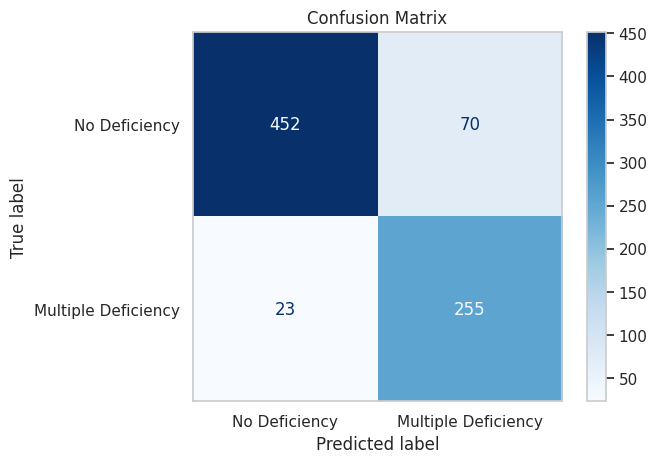

In [45]:
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("=" * 60)
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("=" * 60)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["No Deficiency", "Multiple Deficiency"])
disp.plot(cmap="Blues", values_format="d")
plt.grid(False)
plt.title("Confusion Matrix")
plt.show()

## 5-Fold Cross Validation

In [46]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

roc_auc_scores = cross_val_score(
    estimator=pipeline,
    X=X,
    y=y,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

# Results
print("ROC-AUC Scores per Fold")
print("=" * 60)
print(roc_auc_scores)

print("\nROC-AUC Summary")
print("=" * 60)
print(f"Mean ROC-AUC : {roc_auc_scores.mean():.4f}")
print(f"Std ROC-AUC  : {roc_auc_scores.std():.4f}")


ROC-AUC Scores per Fold
[0.95663728 0.95655889 0.95413325 0.96530362 0.96140329]

ROC-AUC Summary
Mean ROC-AUC : 0.9588
Std ROC-AUC  : 0.0040
